# 05 · Building a shippable v1 detector

Notebook 04 ended with host-only models stuck at about 18% false alarms on my history at 90% recall. That's far too high for a tool people would actually use. This notebook turns what we have into the best possible v1, using the tricks real phishing filters use:

1. **Ensemble.** Average the PSL feature model (E+U) and the n-gram model (D+U). They make different mistakes.
2. **Reputation allowlist.** Trust popular registered domains (Tranco top 10k), never platform pages or shorteners. Most of what people visit is popular, and phishing almost never lives on a top-10k domain it controls.
3. **An honestly chosen threshold.** Split the benchmark in half by domain. Pick the threshold on one half and report results on the other, so the final numbers aren't tuned on the data they're measured on.
4. **Package it** as one `PhishDetector` object, with plain-English reasons for every verdict. That's what the API will load in the next stage.

Same privacy and safety rules as before: history shows only totals, and phishing URLs are defanged.

In [1]:
import io, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.metrics import average_precision_score

from phishdetect.data import load_phiusiil, PROJECT_ROOT
from phishdetect.features import split_host
from phishdetect.models import host_psl_forest, host_psl_boosted, HostCharNgram
from phishdetect.benchmark import (load_tranco, load_openphish, load_chrome_history,
                                   load_umbrella, defang, RAW_DIR)
from phishdetect.detector import PhishDetector, allowlist_from_tranco

pd.set_option("display.max_colwidth", 110)
RANDOM_STATE = 42
TARGET_FA = 0.05        # the false-alarm rate on real legit URLs we're willing to accept
ALLOWLIST_TOP_K = 10_000
SHOW_PRIVATE = False

## 1. Data
Same training data (PhiUSIIL train split plus 50k Umbrella hosts) and the same benchmark as notebook 04.

In [2]:
df = load_phiusiil().drop_duplicates("url").reset_index(drop=True)
y = df["is_phishing"].values
idx_train, _ = train_test_split(np.arange(len(df)), test_size=0.2, stratify=y, random_state=RANDOM_STATE)

tranco  = load_tranco(n=5000, random_state=RANDOM_STATE)
phish   = load_openphish()
history = load_chrome_history(n=1000, max_per_host=3, random_state=RANDOM_STATE)
bench = pd.concat([tranco, history, phish], ignore_index=True)
bench["is_phishing"] = bench["is_phishing"].astype(int)
parts = pd.DataFrame([split_host(u) for u in bench["url"]])
for c in ["host", "registered", "platform"]:
    bench[c] = parts[c].values

umbrella = load_umbrella(n=50_000, top_k=100_000, exclude_domains=set(bench["registered"]),
                         random_state=RANDOM_STATE)
train_urls = np.concatenate([df["url"].values[idx_train], umbrella["url"].values])
train_y = np.concatenate([y[idx_train], np.zeros(len(umbrella), dtype=int)])
print(f"training: {len(train_urls):,} URLs, {train_y.mean():.1%} phishing")
bench.groupby("source").size().rename("urls")

downloaded https://openphish.com/feed.txt -> data/raw/openphish_2026-10-23.txt
training: 238,296 URLs, 33.7% phishing


source
history       374
openphish     300
tranco       5000
Name: urls, dtype: int64

## 2. Split the benchmark: calibrate vs evaluate
Each benchmark URL goes into the **calibration** half or the **evaluation** half based on a hash of its registered domain. Hashing by domain (not by row) keeps every URL from the same site on the same side, so the threshold can't be tuned on `github.com` and then tested on `github.com`.

The halves are small (my history is a few hundred URLs), so expect a few points of noise in the final numbers.

In [3]:
def half(domain: str) -> str:
    return "calib" if int(hashlib.md5(domain.encode()).hexdigest(), 16) % 2 == 0 else "eval"

bench["split"] = bench["registered"].map(half)
LEGIT = "history" if (bench["source"] == "history").any() else "tranco"
print("legit source for threshold picking:", LEGIT)
pd.crosstab(bench["source"], bench["split"])

legit source for threshold picking: history


split,calib,eval
source,,
history,214,160
openphish,135,165
tranco,2520,2480


## 3. Train the components
Three models: D+U and E+U from notebook 04, plus **E+U boosted**, the same features with gradient boosting instead of a random forest. The random forest on 238k rows is huge on disk, which matters once it ships inside a Docker image. If the boosted version scores about the same, it's the better choice for v1.

In [4]:
%%time
def size_mb(obj):
    buf = io.BytesIO(); joblib.dump(obj, buf, compress=3); return buf.tell() / 1e6

components = {
    "D+U": HostCharNgram(),
    "E+U (forest)": host_psl_forest(RANDOM_STATE),
    "E+U (boosted)": host_psl_boosted(RANDOM_STATE),
}
sizes = {}
for name, m in components.items():
    m.fit(train_urls, train_y)
    bench[f"p::{name}"] = m.phish_proba(bench["url"].values)
    sizes[name] = size_mb(m)
    print(f"{name:15s} trained, {sizes[name]:7.1f} MB")

D+U             trained,     3.4 MB
E+U (forest)    trained,    79.6 MB
E+U (boosted)   trained,     0.5 MB
CPU times: user 1min 19s, sys: 6.45 s, total: 1min 25s
Wall time: 33.7 s


## 4. Ensemble and allowlist

In [5]:
bench["p::ensemble"] = (bench["p::D+U"] + bench["p::E+U (boosted)"]) / 2

allowlist = allowlist_from_tranco(RAW_DIR / "tranco_top1m.csv.zip", top_k=ALLOWLIST_TOP_K)
bench["allowlisted"] = [(not p) and (r in allowlist) for p, r in zip(bench["platform"], bench["registered"])]
bench["p::ensemble + allowlist"] = np.where(bench["allowlisted"], 0.0, bench["p::ensemble"])

print(f"allowlist: {len(allowlist):,} registered domains (Tranco top {ALLOWLIST_TOP_K:,}, no platforms or shorteners)")
bench.groupby("source")["allowlisted"].mean().round(3).rename("share allowlisted")

allowlist: 9,991 registered domains (Tranco top 10,000, no platforms or shorteners)


source
history      0.564
openphish    0.007
tranco       0.499
Name: share allowlisted, dtype: float64

**Read the OpenPhish row carefully.** Any phishing URL on an allowlisted domain becomes an automatic miss. That's the price of the allowlist. It's usually phishing hosted on a big company's own service (a Google Form, a SharePoint page) or a compromised popular site.

The Tranco top-10k numbers are now circular (the allowlist *is* the Tranco top 10k), so from here on, judge false alarms by my history and the Tranco **tail** (ranks above 10k, which the allowlist doesn't cover).

In [6]:
lost = bench[(bench["source"] == "openphish") & bench["allowlisted"]][["url", "registered"]].copy()
lost["url"] = lost["url"].map(defang)
print(f"OpenPhish URLs lost to the allowlist: {len(lost)}")
lost.head(15)

OpenPhish URLs lost to the allowlist: 2


,url,registered
5476,hxxps://f005[.]backblazeb2[.]com/file/spectrrrumm01/index[.]html,backblazeb2.com
5584,hxxps://f005[.]backblazeb2[.]com/file/suuiteconnect/indexfcs[.]html,backblazeb2.com


### How big should the allowlist be?
A bigger list trusts more of what people visit but also more domains attackers might abuse. This sweep reads the Tranco file at several sizes.

In [7]:
rows = []
for k in [1_000, 5_000, 10_000, 25_000, 50_000, 100_000]:
    allow_k = allowlist_from_tranco(RAW_DIR / "tranco_top1m.csv.zip", top_k=k)
    hit = pd.Series([(not p) and (r in allow_k) for p, r in zip(bench["platform"], bench["registered"])], index=bench.index)
    rows.append({"top_k": k, "history allowlisted": hit[bench["source"] == "history"].mean(),
                 "OpenPhish lost": hit[bench["source"] == "openphish"].mean()})
pd.DataFrame(rows).set_index("top_k").round(3)

,history allowlisted,OpenPhish lost
top_k,,
1000,0.299,0.000
5000,0.521,0.007
10000,0.564,0.007
25000,0.714,0.007
50000,0.749,0.007
100000,0.794,0.010


## 5. The trade-off curves
Each curve sweeps the threshold from 1 down to 0. Up and to the left is better: more phishing caught for fewer false alarms. The dashed line marks the false-alarm target.

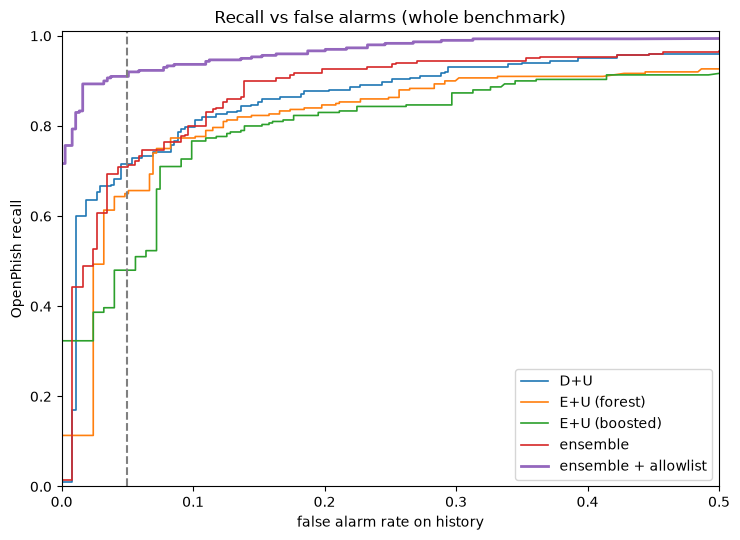

In [8]:
legit_mask = bench["source"] == LEGIT
phish_mask = bench["source"] == "openphish"
systems = ["D+U", "E+U (forest)", "E+U (boosted)", "ensemble", "ensemble + allowlist"]

def curve(p):
    thr = np.unique(np.r_[p[legit_mask], p[phish_mask]])[::-1]
    fa = np.array([(p[legit_mask] >= t).mean() for t in thr])
    rec = np.array([(p[phish_mask] >= t).mean() for t in thr])
    return fa, rec

fig, ax = plt.subplots(figsize=(7.5, 5.5))
for s in systems:
    fa, rec = curve(bench[f"p::{s}"].values)
    ax.plot(fa, rec, label=s, lw=2 if "allowlist" in s else 1.2)
ax.axvline(TARGET_FA, ls="--", c="gray")
ax.set_xlim(0, 0.5); ax.set_ylim(0, 1.01)
ax.set_xlabel(f"false alarm rate on {LEGIT}"); ax.set_ylabel("OpenPhish recall")
ax.legend(loc="lower right"); ax.set_title("Recall vs false alarms (whole benchmark)")
plt.tight_layout(); plt.show()

## 6. Pick thresholds on the calibration half, score on the evaluation half
For each system: on the **calibration** half, find the lowest threshold whose false-alarm rate on legit URLs is at or under `TARGET_FA`. Then apply that threshold to the **evaluation** half and report everything there.

In [9]:
def pick_threshold(legit_scores, target_fa):
    # Lowest threshold t with mean(legit >= t) <= target_fa
    for t in np.sort(np.unique(np.r_[legit_scores, 1.0])):
        if (legit_scores >= t).mean() <= target_fa:
            return float(t)
    return 1.0

cal, ev = bench["split"] == "calib", bench["split"] == "eval"
src = bench["source"]
tail = bench["rank"] > ALLOWLIST_TOP_K

def rate(mask, flagged):
    return flagged[mask].mean() if mask.any() else np.nan

rows, thresholds = [], {}
for s in systems:
    p = bench[f"p::{s}"]
    t = pick_threshold(p[cal & (src == LEGIT)].values, TARGET_FA)
    thresholds[s] = t
    f = p >= t
    rows.append({
        "system": s, "threshold": t,
        "history FA": rate(ev & (src == "history"), f),
        "Tranco tail FA": rate(ev & (src == "tranco") & tail, f),
        "recall": rate(ev & (src == "openphish"), f),
        "recall (platform)": rate(ev & (src == "openphish") & bench["platform"], f),
        "recall (other)": rate(ev & (src == "openphish") & ~bench["platform"], f),
        "size MB": sizes.get(s, np.nan),
    })
scoreboard = pd.DataFrame(rows).set_index("system").round(3)
scoreboard.loc["ensemble", "size MB"] = scoreboard.loc["ensemble + allowlist", "size MB"] = \
    round(sizes["D+U"] + sizes["E+U (boosted)"], 1)
scoreboard

,threshold,history FA,Tranco tail FA,recall,recall (platform),recall (other),size MB
system,,,,,,,
D+U,0.838,0.000,0.044,0.576,0.862,0.197,3.390
E+U (forest),0.985,0.000,0.001,0.127,0.223,0.000,79.625
E+U (boosted),0.988,0.000,0.001,0.327,0.574,0.000,0.466
ensemble,0.887,0.000,0.004,0.491,0.787,0.099,3.900
ensemble + allowlist,0.368,0.012,0.224,0.879,1.000,0.718,3.900


Compare with notebook 04, where the best model needed about 18% false alarms to reach 90% recall. Here every system is held to the same false-alarm budget, so the question becomes: **how much phishing does each one catch while staying under 5%?**

## 7. Package v1
The ensemble plus the allowlist, with the threshold picked on the calibration half.

In [10]:
detector = PhishDetector(
    models={"E+U (boosted)": components["E+U (boosted)"], "D+U": components["D+U"]},
    allowlist=allowlist,
    threshold=thresholds["ensemble + allowlist"],
    version="v1",
)
row = scoreboard.loc["ensemble + allowlist"]
snapshots = sorted(RAW_DIR.glob("openphish_*.txt"))
detector.metadata = {
    "training_data": f"PhiUSIIL train split + {len(umbrella):,} Umbrella hostnames",
    "allowlist": f"Tranco top {ALLOWLIST_TOP_K:,} registered domains, minus platforms and shorteners",
    "threshold_policy": f"lowest threshold with <= {TARGET_FA:.0%} false alarms on {LEGIT} (calibration half)",
    "openphish_snapshot": snapshots[-1].stem.split("_", 1)[1] if snapshots else None,
    "eval_history_fa": row["history FA"], "eval_tranco_tail_fa": row["Tranco tail FA"],
    "eval_recall": row["recall"],
}
out = PROJECT_ROOT / "models" / "detector_v1.joblib"
detector.save(out)
print(f"saved {out.relative_to(PROJECT_ROOT)} ({out.stat().st_size / 1e6:.1f} MB) and {out.with_suffix('.json').name}")

saved models/detector_v1.joblib (3.9 MB) and detector_v1.json


### Try it
Load the saved file fresh (exactly what the API will do) and explain a few made-up and public URLs. The phishing-style ones are invented examples.

In [11]:
v1 = PhishDetector.load(out)
examples = [
    "https://docs.google.com/document/d/1aBcD/edit",
    "https://github.com/scikit-learn/scikit-learn",
    "https://www.vcu.edu/admissions/graduate/",
    "https://someones-portfolio.github.io/",
    "http://paypal-account-verify.xyz/login",
    "https://secure-login-appleid.webflow.io/",
    "http://198.51.100.7/bank/login",
    "https://bit.ly/3xYz",
]
explained = pd.DataFrame([v1.explain(u) for u in examples])
explained["reasons"] = explained["reasons"].map(lambda r: "; ".join(r))
explained[["url", "verdict", "score", "allowlisted", "reasons"]]

,url,verdict,score,allowlisted,reasons
0,https://docs.google.com/document/d/1aBcD/edit,legit,0.0000,True,google.com is on the popular-domain allowlist
1,https://github.com/scikit-learn/scikit-learn,legit,0.0000,True,github.com is on the popular-domain allowlist
2,https://www.vcu.edu/admissions/graduate/,legit,0.0275,False,
3,https://someones-portfolio.github.io/,phishing,0.9850,False,hosted on a free platform; the site name 'someones-portfolio' was chosen by whoever signed up
4,http://paypal-account-verify.xyz/login,phishing,0.9977,False,"contains a brand name, but the site isn't owned by that brand; hostname contains words common in phishing ..."
5,https://secure-login-appleid.webflow.io/,phishing,0.9979,False,hosted on a free platform; the site name 'secure-login-appleid' was chosen by whoever signed up; contains ...
6,http://198.51.100.7/bank/login,phishing,0.9138,False,uses a raw IP address instead of a domain name; site name is mostly digits
7,https://bit.ly/3xYz,phishing,0.9928,False,URL shortener; the real destination is hidden


In [12]:
h = bench[src == "history"]
if SHOW_PRIVATE:
    display(h.nlargest(20, "p::ensemble + allowlist")[["host", "allowlisted", "p::ensemble + allowlist"]])
else:
    t = thresholds["ensemble + allowlist"]
    print(f"{len(h)} history URLs; v1 flags {(h['p::ensemble + allowlist'] >= t).sum()} at threshold {t:.3f}.")

374 history URLs; v1 flags 12 at threshold 0.368.


## 8. Save the scoreboard

In [13]:
from datetime import date
(PROJECT_ROOT / "reports").mkdir(exist_ok=True)
scoreboard.assign(notebook="05", date=date.today().isoformat(), target_fa=TARGET_FA).to_csv(
    PROJECT_ROOT / "reports" / "scoreboard_05.csv")
print("saved reports/scoreboard_05.csv")

saved reports/scoreboard_05.csv


## Results log
Fill in from section 6 (evaluation half).

| system | threshold | history FA | Tranco tail FA | recall | recall (platform) | recall (other) | size MB |
|---|---|---|---|---|---|---|---|
| D+U | | | | | | | |
| E+U (forest) | | | | | | | |
| E+U (boosted) | | | | | | | |
| ensemble | | | | | | | |
| ensemble + allowlist | | | | | | | |

Questions for the journal:
1. At a 5% false-alarm budget, how much recall does each piece (ensemble, allowlist) buy?
2. Did the boosted model match the forest at a fraction of the size?
3. How many OpenPhish URLs did the allowlist cost, and what kind were they?
4. Is v1 good enough to put behind an API as a demo? (It doesn't need to be perfect, just honest about its numbers.)